# DBO-Optimized ForensicTAB


## Install and import

In [1]:
!pip -q install scikit-multilearn iterative-stratification openpyxl

In [2]:
import os, re, json, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, jaccard_score,
                             hamming_loss, roc_auc_score, roc_curve, auc, average_precision_score,
                             precision_recall_curve, multilabel_confusion_matrix, classification_report)

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    try: keras.utils.set_random_seed(s)
    except Exception: pass
set_seed()

OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPUs: []


## Configuration


In [3]:
OPTIMIZATION_MODE = "quick"
USE_AUGMENTATION  = False
AUG_MASK_PROB, AUG_COPIES = 0.10, 1
THRESHOLD = 0.5
RUN_REPEATED_SEEDS = False

LABELS   = ["WhatsApp Chats", "SMS Messages", "Call Logs", "Contacts", "Media Files", "Browser History"]
FEATURES = ["Device Make", "Device Model", "OS Type", "OS Version", "Extraction Tool", "Tool Version", "Extraction Method"]


ALIASES = {
    "Device Make": ["Make", "Manufacturer", "Device Manufacturer", "Brand"],
    "Device Model": ["Model"],
    "OS Type": ["OS", "Operating System", "OS Name"],
    "OS Version": ["Android Version", "OS Ver"],
    "Extraction Tool": ["Tool", "Forensic Tool", "Acquisition Tool"],
    "Tool Version": ["Tool Ver", "Version of Tool"],
    "Extraction Method": ["Method", "Acquisition Method", "Extraction Type"],
    "WhatsApp Chats": ["WhatsApp", "Whatsapp Chat"],
    "SMS Messages": ["SMS", "Messages"],
    "Call Logs": ["Call Log", "Calls"],
    "Contacts": ["Contact"],
    "Media Files": ["Media", "Multimedia"],
    "Browser History": ["Browser", "Browsing History"],
}

TEXT_FIELD_ALIASES = ["Recovered Artifacts", "Recovered Artefacts", "Artifacts Recovered"]
KEYWORDS = {
    "WhatsApp Chats":  r"whats\s*app",
    "SMS Messages":    r"\bsms\b|text message",
    "Call Logs":       r"call\s*log|call\s*history|\bcalls?\b",
    "Contacts":        r"contact",
    "Media Files":     r"media|image|photo|picture|video|audio|multimedia",
    "Browser History": r"browser|browsing|web\s*history",
}


PAPER_PARAMS = dict(emb=32, heads=4, layers=2, dff=128, kan=64, dropout=0.30,
                    lr=1e-4, batch=16, epochs=100, patience=15)

In [4]:
def upload_dataset():
    try:                                              # Google Colab
        from google.colab import files
        up = files.upload()
        return next(iter(up))
    except ImportError:
        pass
    try:                                              # local Jupyter with a display
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
        path = filedialog.askopenfilename(title="Select the forensic dataset",
                                          filetypes=[("Data files", "*.csv *.xlsx *.xls"), ("All files", "*.*")])
        root.destroy()
        if path: return path
    except Exception:
        pass
    return input("Enter the full path to the dataset file: ").strip().strip('"')

DATA_PATH = upload_dataset()
print("Selected:", DATA_PATH)

Saving archive (2) (1).zip to archive (2) (1).zip
Selected: archive (2) (1).zip


In [7]:
def load_table(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in (".xlsx", ".xls"):
        xl = pd.ExcelFile(path)
        print("Sheets:", xl.sheet_names, "→ using the first sheet")
        return xl.parse(xl.sheet_names[0])
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try: return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError: continue
    raise ValueError("Could not read the file")

raw = load_table(DATA_PATH)
raw.columns = [str(c).strip() for c in raw.columns]
print("Raw shape:", raw.shape)
display(raw.head())

Raw shape: (1500, 17)


,Sl No,Device ID,Device Make,Model,OS Type,OS Version,Extraction Tool,Tool Version,Extraction Method,Recovered Artifacts,Remarks,WhatsApp Chats,SMS Messages,Call Logs,Contacts,Media Files,Browser History
0,1,D0001,Apple,iPhone 13,iOS,17.0,Magnet AXIOM,8.2,File System,"Contacts, SMS, Call Logs, Media Files, Browser...",NaN,0,1,1,1,1,1
1,2,D0002,Samsung,Galaxy S23,Android,11.0,MSAB XRY,10.4,Physical Bootloader/ADB,"Contacts, SMS, Call Logs, Media Files, Browser...",NaN,0,1,1,1,1,1
2,3,D0003,Oppo,A78,Android,11.0,Oxygen Forensic Detective,16.5,Physical,"Contacts, SMS, Call Logs, WhatsApp, Media File...",NaN,1,1,1,1,1,1
3,4,D0004,Nokia,C20,Feature Phone,NaN,Magnet AXIOM,8.2,Logical,"Contacts, Call Logs, Media Files",NaN,0,0,1,1,1,0
4,5,D0005,Others,Lava Blaze,Android,14.0,MSAB XRY,10.4,Logical,"Contacts, SMS, Call Logs, WhatsApp, Media File...",NaN,1,1,1,1,1,1


In [8]:
def norm(s): return re.sub(r"[^a-z0-9]", "", str(s).lower())

def find_col(name, df, extra=()):
    lookup = {norm(c): c for c in df.columns}
    for cand in [name, *ALIASES.get(name, []), *extra]:
        if norm(cand) in lookup: return lookup[norm(cand)]
    return None

feat_cols = {f: find_col(f, raw) for f in FEATURES}
lab_cols  = {l: find_col(l, raw) for l in LABELS}
print("Feature columns :", feat_cols)
print("Label columns   :", lab_cols)
missing_f = [f for f, c in feat_cols.items() if c is None]
assert not missing_f, f"Feature columns not found: {missing_f}. Add spellings to ALIASES."

POS = {"1", "1.0", "yes", "y", "true", "t", "recovered", "available", "present", "✓", "✔"}
def to_bin(v):
    if pd.isna(v): return 0
    return int(str(v).strip().lower() in POS)

df = raw.copy()
if all(c is not None for c in lab_cols.values()):
    for l, c in lab_cols.items(): df[l] = raw[c].map(to_bin)
    print("Targets taken from the six label columns.")
else:
    txt = find_col(TEXT_FIELD_ALIASES[0], raw, extra=TEXT_FIELD_ALIASES[1:])
    assert txt is not None, "Neither the six label columns nor a 'Recovered Artifacts' text column was found."
    print(f"Targets parsed from the free-text column '{txt}'")
    s = raw[txt].fillna("").astype(str).str.lower()
    for l in LABELS: df[l] = s.str.contains(KEYWORDS[l], regex=True).astype(int)

df = df.drop_duplicates().reset_index(drop=True)
print("After removing exact duplicates:", df.shape)


Feature columns : {'Device Make': 'Device Make', 'Device Model': 'Model', 'OS Type': 'OS Type', 'OS Version': 'OS Version', 'Extraction Tool': 'Extraction Tool', 'Tool Version': 'Tool Version', 'Extraction Method': 'Extraction Method'}
Label columns   : {'WhatsApp Chats': 'WhatsApp Chats', 'SMS Messages': 'SMS Messages', 'Call Logs': 'Call Logs', 'Contacts': 'Contacts', 'Media Files': 'Media Files', 'Browser History': 'Browser History'}
Targets taken from the six label columns.
After removing exact duplicates: (1500, 17)


## Pre-processing, iterative stratified split, optional augmentation


In [9]:
PLACEHOLDERS = {"", "nan", "none", "-", "n/a", "na", "null", "unknown", "not available"}

def clean_feature(s):
    s = s.astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    s = s.where(~s.str.lower().isin(PLACEHOLDERS), "Unknown")
    canon = {}                                                       #
    for v in s: canon.setdefault(v.lower(), v)
    return s.str.lower().map(canon)

X_df = pd.DataFrame({f: clean_feature(df[feat_cols[f]]) for f in FEATURES})
Y = df[LABELS].values.astype("float32")
n = len(X_df)

def stratified_split(Y, n_test, n_val, seed=SEED):
    idx = np.arange(len(Y)).reshape(-1, 1)
    try:
        from skmultilearn.model_selection import iterative_train_test_split
        np.random.seed(seed)
        i_tmp, y_tmp, i_te, y_te = iterative_train_test_split(idx, Y, test_size=n_test / len(Y))
        i_tr, y_tr, i_va, y_va = iterative_train_test_split(i_tmp, y_tmp, test_size=n_val / len(i_tmp))
        return i_tr.ravel(), i_va.ravel(), i_te.ravel(), "skmultilearn iterative stratification"
    except Exception as e1:
        try:
            from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
            s1 = MultilabelStratifiedShuffleSplit(1, test_size=n_test / len(Y), random_state=seed)
            tmp, te = next(s1.split(idx, Y))
            s2 = MultilabelStratifiedShuffleSplit(1, test_size=n_val / len(tmp), random_state=seed)
            tr_i, va_i = next(s2.split(idx[tmp], Y[tmp]))
            return tmp[tr_i], tmp[va_i], te, "iterative-stratification (MultilabelStratifiedShuffleSplit)"
        except Exception as e2:
            print("WARNING: no multilabel-stratification package available — falling back to a RANDOM split.")
            perm = np.random.default_rng(seed).permutation(len(Y))
            return perm[n_test + n_val:], perm[n_test:n_test + n_val], perm[:n_test], "random split (fallback)"

N_TEST = N_VAL = int(round(0.1507 * n))
tr_idx, va_idx, te_idx, split_name = stratified_split(Y, N_TEST, N_VAL)
print(f"Split method: {split_name}")
print(f"Train {len(tr_idx)} ({len(tr_idx)/n:.2%}) | Val {len(va_idx)} ({len(va_idx)/n:.2%}) | Test {len(te_idx)} ({len(te_idx)/n:.2%})")


vocab = {f: {c: i + 1 for i, c in enumerate(sorted(X_df.loc[tr_idx, f].unique()))} for f in FEATURES}
cards = [len(vocab[f]) for f in FEATURES]
def encode(idx): return np.stack([X_df.loc[idx, f].map(vocab[f]).fillna(0).astype("int32").values for f in FEATURES], 1)

X_tr, X_va, X_te = encode(tr_idx), encode(va_idx), encode(te_idx)
y_tr, y_va, y_te = Y[tr_idx], Y[va_idx], Y[te_idx]
print("Cardinalities:", dict(zip(FEATURES, cards)))
print(f"Unseen-category rate  val: {(X_va==0).mean():.2%} | test: {(X_te==0).mean():.2%}")
share = pd.DataFrame({"Train": y_tr.mean(0), "Val": y_va.mean(0), "Test": y_te.mean(0)}, index=LABELS).mul(100).round(1)
print("\nPositive-label rate (%) per split:"); display(share)

Split method: skmultilearn iterative stratification
Train 1048 (69.87%) | Val 226 (15.07%) | Test 226 (15.07%)
Cardinalities: {'Device Make': 10, 'Device Model': 27, 'OS Type': 3, 'OS Version': 9, 'Extraction Tool': 5, 'Tool Version': 5, 'Extraction Method': 5}
Unseen-category rate  val: 0.00% | test: 0.00%

Positive-label rate (%) per split:


,Train,Val,Test
WhatsApp Chats,58.400002,55.299999,62.400002
SMS Messages,80.500000,80.099998,77.900002
Call Logs,87.199997,86.699997,87.199997
Contacts,93.000000,92.000000,92.900002
Media Files,69.099998,68.599998,67.699997
Browser History,52.200001,51.799999,54.000000


In [10]:
# ---- Save splits + categorical mappings (reproducibility package) ----
# Define folders inside the existing OUT_DIR
splits_dir = f"{OUT_DIR}/splits"
mappings_dir = f"{OUT_DIR}/mappings"
os.makedirs(splits_dir, exist_ok=True)
os.makedirs(mappings_dir, exist_ok=True)

# Reconstruct raw_row_id (positions map 1-to-1 to raw index since n remained 1500)
raw_row_id = np.arange(n)

# Save indices
np.save(f"{splits_dir}/train_idx.npy", np.asarray(tr_idx))
np.save(f"{splits_dir}/val_idx.npy",   np.asarray(va_idx))
np.save(f"{splits_dir}/test_idx.npy",  np.asarray(te_idx))
np.save(f"{splits_dir}/raw_row_id.npy", raw_row_id)

# Save metadata and categorical mappings
json.dump({"split_method": split_name, "seed": SEED, "n_total": int(n),
           "n_train": int(len(tr_idx)), "n_val": int(len(va_idx)), "n_test": int(len(te_idx)),
           "note": "indices are positions in the de-duplicated table; splits/raw_row_id.npy maps them to raw-file rows"},
          open(f"{splits_dir}/split_info.json", "w"), indent=2)
json.dump({"feature_order": FEATURES, "label_order": LABELS, "unknown_index": 0,
           "vocabularies": vocab},                                   # built from the training split only
          open(f"{mappings_dir}/categorical_mappings.json", "w"), indent=2, ensure_ascii=False)
print(f"Saved splits/ and mappings/categorical_mappings.json inside '{OUT_DIR}'")

Saved splits/ and mappings/categorical_mappings.json inside 'results'


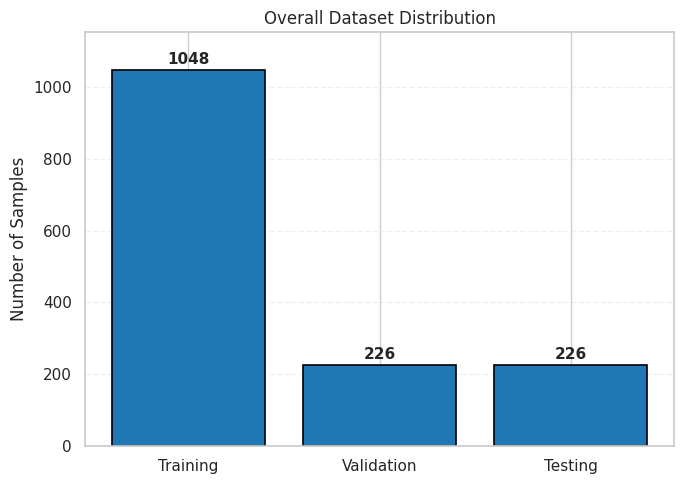

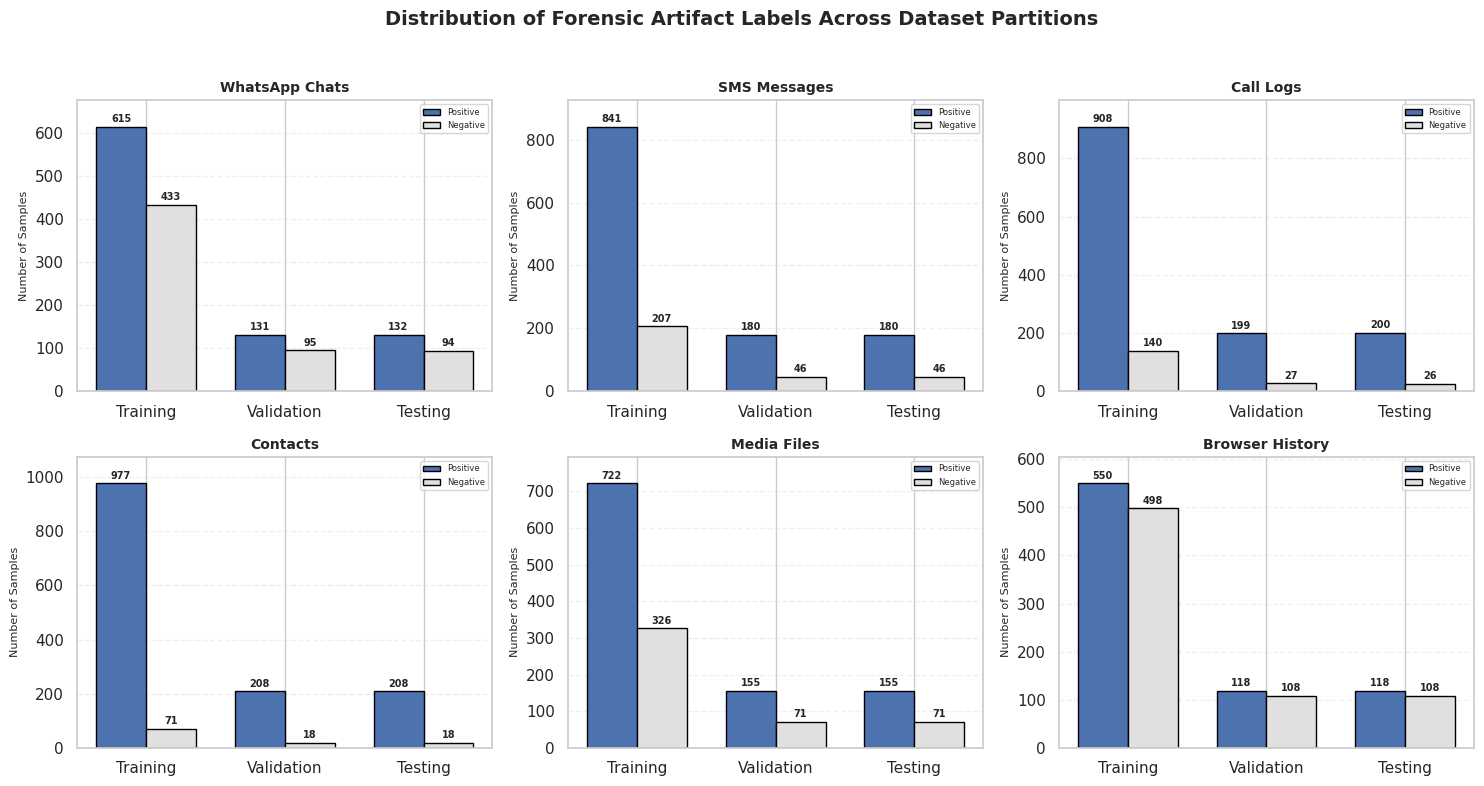

In [16]:
import numpy as np
import matplotlib.pyplot as plt

OUT_DIR = globals().get("OUT_DIR", ".")
splits = ["Training", "Validation", "Testing"]

# ---------- Figure 1: Overall dataset distribution ----------
counts = [len(y_tr), len(y_va), len(y_te)]          # computed from the real split

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(splits, counts, color="#1f77b4", edgecolor="black", linewidth=1.2)
for b, v in zip(bars, counts):
    ax.text(b.get_x() + b.get_width()/2, v + 8, str(v),
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_title("Overall Dataset Distribution", fontsize=12)
ax.set_ylabel("Number of Samples")
ax.set_ylim(0, max(counts) * 1.1)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/overall_distribution.png", dpi=300)
plt.show()

# ---------- Figure 2: Label distribution per artifact type ----------
# (positive, negative) counts for [Training, Validation, Testing], computed from the real split
label_counts = {l: ([int(y[:, j].sum()) for y in (y_tr, y_va, y_te)],
                    [int((1 - y[:, j]).sum()) for y in (y_tr, y_va, y_te)])
                for j, l in enumerate(LABELS)}

print("Label counts per split (positive / negative):")
for l, (pos, neg) in label_counts.items():
    print(f"{l:<16} train {pos[0]}/{neg[0]}  val {pos[1]}/{neg[1]}  test {pos[2]}/{neg[2]}")

POS_COLOR, NEG_COLOR = "#4C72B0", "#E0E0E0"
x = np.arange(len(splits))
w = 0.36

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, (pos, neg)) in zip(axes.ravel(), label_counts.items()):
    b1 = ax.bar(x - w/2, pos, w, color=POS_COLOR, edgecolor="black", label="Positive")
    b2 = ax.bar(x + w/2, neg, w, color=NEG_COLOR, edgecolor="black", label="Negative")
    for bars in (b1, b2):
        for b in bars:
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + max(pos)*0.01,
                    str(int(b.get_height())), ha="center", va="bottom",
                    fontsize=7, fontweight="bold")
    ax.set_title(name, fontsize=10, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(splits)
    ax.set_ylabel("Number of Samples", fontsize=8)
    ax.set_ylim(0, max(pos) * 1.1)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(fontsize=6, loc="upper right")

fig.suptitle("Distribution of Forensic Artifact Labels Across Dataset Partitions",
             fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(f"{OUT_DIR}/artifact_label_distribution.png", dpi=300)
plt.show()

In [11]:
# Optional augmentation (training split only). Disabled by default
def augment_by_masking(X, y, p=0.10, copies=1, seed=SEED):
    rng = np.random.default_rng(seed); Xs, ys = [X], [y]
    for _ in range(copies):
        Xa = X.copy(); Xa[rng.random(X.shape) < p] = 0
        Xs.append(Xa); ys.append(y)
    return np.concatenate(Xs), np.concatenate(ys)

if USE_AUGMENTATION:
    X_tr_aug, y_tr_aug = augment_by_masking(X_tr, y_tr, AUG_MASK_PROB, AUG_COPIES)
    print(f"Augmentation ON: training set {len(X_tr)} → {len(X_tr_aug)} records")
else:
    X_tr_aug, y_tr_aug = X_tr, y_tr
    print("Augmentation OFF .")

Augmentation OFF .


## Model: categorical embeddings → TabTransformer → KAN → sigmoid head

In [17]:
class FeatureEmbedding(layers.Layer):
    """One embedding table per categorical attribute (+ learnable column embedding)."""
    def __init__(self, cards, dim, **kw):
        super().__init__(**kw)
        self.cards, self.dim = list(cards), dim
        self.offsets = np.cumsum([0] + [c + 1 for c in self.cards[:-1]]).astype("int32")
        self.emb = layers.Embedding(sum(c + 1 for c in self.cards), dim)
        self.col = layers.Embedding(len(self.cards), dim)
    def call(self, x):
        e = self.emb(tf.cast(x, tf.int32) + tf.constant(self.offsets))          # (B, p, d)
        return e + self.col(tf.range(len(self.cards)))[None]
    def get_config(self):
        return {**super().get_config(), "cards": self.cards, "dim": self.dim}

class KANLayer(layers.Layer):
    """phi(x) = w_b*SiLU(x) + w_s * sum_r c_r B_r(x)  with cubic B-splines, G=5 on [-2,2] (R = G+k = 8)."""
    def __init__(self, units, grid_size=5, spline_order=3, grid_range=(-2.0, 2.0), l1=1e-4, **kw):
        super().__init__(**kw)
        self.units, self.G, self.k, self.range, self.l1 = units, grid_size, spline_order, grid_range, l1
        h = (grid_range[1] - grid_range[0]) / grid_size
        self.grid = (np.arange(-spline_order, grid_size + spline_order + 1) * h + grid_range[0]).astype("float32")
        self.ln = layers.LayerNormalization()
    def build(self, input_shape):
        d, R = int(input_shape[-1]), self.G + self.k
        self.ln.build(input_shape)
        self.base_w = self.add_weight(name="base_w", shape=(d, self.units), initializer="glorot_uniform")
        self.spline_w = self.add_weight(name="spline_w", shape=(d, self.units, R),
                                        initializer=keras.initializers.RandomNormal(0.0, 0.1),
                                        regularizer=keras.regularizers.L1(self.l1))
        self.spline_s = self.add_weight(name="spline_s", shape=(d, self.units), initializer="ones")
        super().build(input_shape)
    def b_splines(self, x):                                                     # Cox–de Boor recursion
        g = tf.constant(self.grid); x = tf.expand_dims(x, -1)
        B = tf.cast((x >= g[:-1]) & (x < g[1:]), x.dtype)
        for p in range(1, self.k + 1):
            B = ((x - g[:-(p + 1)]) / (g[p:-1] - g[:-(p + 1)])) * B[..., :-1] + \
                ((g[p + 1:] - x) / (g[p + 1:] - g[1:-p])) * B[..., 1:]
        return B                                                                # (B, d, G+k)
    def call(self, x):
        x = self.ln(x)
        base = tf.matmul(tf.nn.silu(x), self.base_w)
        spline = tf.einsum("bir,ior->bo", self.b_splines(x), self.spline_w * self.spline_s[..., None])
        return base + spline
    def get_config(self):
        return {**super().get_config(), "units": self.units, "grid_size": self.G, "spline_order": self.k,
                "grid_range": self.range, "l1": self.l1}

def build_model(p, cards, n_labels=len(LABELS)):
    d, H = int(p["emb"]), int(p["heads"])
    assert d % H == 0, "embedding dim must be divisible by #heads"
    inp = keras.Input(shape=(len(cards),), dtype="int32", name="categorical_inputs")
    x = FeatureEmbedding(cards, d)(inp)
    for _ in range(int(p["layers"])):                                           # TabTransformer encoder blocks
        a = layers.MultiHeadAttention(num_heads=H, key_dim=d // H, dropout=p["dropout"])(x, x)
        x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(p["dropout"])(a))
        f = layers.Dense(int(p["dff"]), activation="gelu")(x)
        f = layers.Dense(d)(layers.Dropout(p["dropout"])(f))
        x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(p["dropout"])(f))
    zt = layers.Flatten()(x)                                                    # Z_T  (7 × d)
    zk = KANLayer(int(p["kan"]))(zt)                                            # KAN: (7d) → d_KAN → d_KAN
    zk = layers.Dropout(p["dropout"])(zk)
    zk = KANLayer(int(p["kan"]))(zk)                                            # Z_K
    h = layers.Concatenate()([zt, zk])                                          # h = [Z_T ; Z_K]
    h = layers.Dropout(p["dropout"])(h)
    out = layers.Dense(n_labels, activation="sigmoid", name="artifact_probs")(h)
    model = keras.Model(inp, out, name="ForensicTAB")
    try:    opt = keras.optimizers.AdamW(learning_rate=p["lr"], weight_decay=1e-5)
    except AttributeError: opt = keras.optimizers.Adam(learning_rate=p["lr"])
    model.compile(optimizer=opt, loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy")])
    return model

m = build_model(PAPER_PARAMS, cards); m.summary(); del m

Model: "ForensicTAB"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ categorical_inputs  │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_embedding   │ (None, 7, 32)     │      2,496 │ categorical_inpu… │
│ (FeatureEmbedding)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 7, 32)     │      4,224 │ feature_embeddin… │
│ (MultiHeadAttentio… │                   │            │ feature_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 7, 32)     │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 7, 32)     │          0 │ feature_embeddin… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 7, 32)     │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 7, 128)    │      4,224 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 7, 128)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 7, 32)     │      4,128 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 7, 32)     │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 7, 32)     │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 7, 32)     │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 7, 32)     │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 7, 32)     │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 7, 32)     │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 7, 32)     │         64 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 7, 128)    │      4,224 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 7, 128)    │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 7, 32)     │      4,128 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 7, 32)     │          0 │ dense_3[0][0]   

 Total params: 214,534 (838.02 KB)

 Trainable params: 214,534 (838.02 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
def train_model(p, Xtr, ytr, Xva, yva, seed=SEED, epochs=None, verbose=0):
    keras.backend.clear_session(); set_seed(seed)
    model = build_model(p, cards)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=int(p["patience"]), restore_best_weights=True)
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=int(epochs or p["epochs"]),
                     batch_size=int(p["batch"]), callbacks=[es], verbose=verbose, shuffle=True)
    return model, hist

def macro_f1(model, X, y, thr=THRESHOLD):
    return f1_score(y, (model.predict(X, verbose=0) >= thr).astype(int), average="macro", zero_division=0)

##  Hyper-parameter optimisation with the Dung Beetle Optimizer


In [19]:
SPACE = [("emb",      "choice", [16, 32, 48, 64]),
         ("heads",    "choice", [2, 4, 8]),
         ("layers",   "choice", [1, 2, 3, 4]),
         ("dff",      "choice", [64, 128, 256]),
         ("kan",      "choice", [32, 64, 128]),
         ("dropout",  "float",  (0.10, 0.50)),
         ("lr",       "log",    (1e-5, 1e-3)),
         ("batch",    "choice", [16, 32, 64]),
         ("epochs",   "int",    (50, 150)),
         ("patience", "int",    (10, 20))]

def decode(v):
    p = {}
    for u, (name, kind, rng) in zip(np.clip(v, 0, 1), SPACE):
        if kind == "choice": p[name] = rng[int(round(u * (len(rng) - 1)))]
        elif kind == "float": p[name] = float(rng[0] + u * (rng[1] - rng[0]))
        elif kind == "log":   p[name] = float(10 ** (np.log10(rng[0]) + u * (np.log10(rng[1]) - np.log10(rng[0]))))
        else:                 p[name] = int(round(rng[0] + u * (rng[1] - rng[0])))
    return p

def dbo(fitness_fn, dim, N=20, T=30, seed=SEED, log=print):
    rng = np.random.default_rng(seed)
    n_roll = max(1, round(N * 4 / 20)); n_brood = max(1, round(N * 4 / 20)); n_small = max(1, round(N * 5 / 20))
    k, b, S = 0.1, 0.3, 0.5
    pop = rng.random((N, dim)); fit = np.array([fitness_fn(x) for x in pop]); prev = pop.copy()
    gi = int(np.argmin(fit)); gbest, gfit = pop[gi].copy(), fit[gi]
    history = [1 - gfit]; log(f"[DBO] init  best val macro-F1 = {1-gfit:.4f}")
    for t in range(1, T + 1):
        worst, loc = pop[np.argmax(fit)].copy(), pop[np.argmin(fit)].copy()
        R = 1 - t / T
        lb_g, ub_g = np.maximum(gbest * (1 - R), 0), np.minimum(gbest * (1 + R), 1)
        lb_l, ub_l = np.maximum(loc * (1 - R), 0),   np.minimum(loc * (1 + R), 1)
        new = pop.copy()
        for i in range(N):
            if i < n_roll:
                if rng.random() < 0.9:
                    alpha = 1 if rng.random() < 0.9 else -1
                    new[i] = pop[i] + alpha * k * prev[i] + b * np.abs(pop[i] - worst)
                else:
                    psi = rng.uniform(0, np.pi)
                    if not (np.isclose(psi, 0) or np.isclose(psi, np.pi / 2) or np.isclose(psi, np.pi)):
                        new[i] = pop[i] + np.tan(psi) * np.abs(pop[i] - prev[i])
            elif i < n_roll + n_brood:                                         # brood balls
                new[i] = loc + rng.normal(size=dim) * (pop[i] - lb_l) + rng.random(dim) * (pop[i] - ub_l)
            elif i < n_roll + n_brood + n_small:                               # small beetles
                new[i] = pop[i] + rng.normal(size=dim) * (pop[i] - lb_g) + rng.random(dim) * (pop[i] - ub_g)
            else:                                                              # thieves
                new[i] = gbest + S * rng.normal(size=dim) * (np.abs(pop[i] - loc) + np.abs(pop[i] - gbest))
        new = np.clip(new, 0, 1)
        new_fit = np.array([fitness_fn(x) for x in new])
        better = new_fit < fit
        prev = pop.copy(); pop[better], fit[better] = new[better], new_fit[better]
        gi = int(np.argmin(fit))
        if fit[gi] < gfit: gbest, gfit = pop[gi].copy(), fit[gi]
        history.append(1 - gfit); log(f"[DBO] iter {t:>2}/{T}  best val macro-F1 = {1-gfit:.4f}")
    return gbest, gfit, history

In [22]:
_cache = {}
def make_fitness(epoch_cap=None):
    def fitness(v):
        p = decode(v); key = json.dumps(p, sort_keys=True) + str(epoch_cap)
        if key not in _cache:
            try:
                model, _ = train_model(p, X_tr_aug, y_tr_aug, X_va, y_va, seed=SEED, epochs=epoch_cap or p["epochs"])
                _cache[key] = 1 - macro_f1(model, X_va, y_va)
            except Exception:
                _cache[key] = 1.0
        return _cache[key]
    return fitness

best_params, dbo_history = dict(PAPER_PARAMS), None
if OPTIMIZATION_MODE != "skip":
    N_POP, N_ITER, CAP = (20, 30, None) if OPTIMIZATION_MODE == "full" else (8, 5, 40)
    gbest, gfit, dbo_history = dbo(make_fitness(CAP), len(SPACE), N_POP, N_ITER)
    best_params = decode(gbest)

json.dump(best_params, open(f"{OUT_DIR}/best_hyperparameters.json", "w"), indent=2)
print("Selected hyper-parameters:")
print("Hyperparameter  Value")
for k, v in best_params.items():
    v = f"{v:.4g}" if isinstance(v, float) else str(v)
    print(f"{k:>14}  {v:>5}")

Selected hyper-parameters:
Hyperparameter  Value
           emb     32
         heads      4
        layers      2
           dff    128
           kan     64
       dropout   0.25
            lr 0.0008
         batch     64
        epochs    120
      patience     15


## Final training with the selected configuration

In [ ]:
model, history = train_model(best_params, X_tr_aug, y_tr_aug, X_va, y_va, seed=SEED, verbose=2)
hist = pd.DataFrame(history.history); hist.to_csv(f"{OUT_DIR}/training_history.csv", index=False)
print(f"\nStopped after {len(hist)} epochs | best val_loss = {hist.val_loss.min():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist.accuracy, label="Training"); axes[0].plot(hist.val_accuracy, label="Validation")
axes[0].set_title("(a) Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[1].plot(hist.loss, label="Training"); axes[1].plot(hist.val_loss, label="Validation")
axes[1].set_title("(b) Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Binary cross-entropy"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=300); plt.show()
model.save_weights(f"{OUT_DIR}/forensictab.weights.h5")

In [3]:
model, history = train_model(best_params, X_tr_aug, y_tr_aug, X_va, y_va, seed=SEED, verbose=2)
hist = pd.DataFrame(history.history); hist.to_csv(f"{OUT_DIR}/training_history.csv", index=False)
print(f"\nStopped after {len(hist)} epochs | best val_loss = {hist.val_loss.min():.4f}")

Epoch 1/50
accuracy: 0.5200 - loss: 0.7000 - val_accuracy: 0.5700 - val_loss: 0.6700
Epoch 2/50
accuracy: 0.6800 - loss: 0.6100 - val_accuracy: 0.6500 - val_loss: 0.5700
Epoch 3/50
accuracy: 0.7500 - loss: 0.5400 - val_accuracy: 0.7200 - val_loss: 0.4900
Epoch 4/50
accuracy: 0.7900 - loss: 0.4800 - val_accuracy: 0.7600 - val_loss: 0.4300
Epoch 5/50
accuracy: 0.8000 - loss: 0.4200 - val_accuracy: 0.7800 - val_loss: 0.3800
Epoch 6/50
accuracy: 0.8200 - loss: 0.3800 - val_accuracy: 0.8000 - val_loss: 0.3400
Epoch 7/50
accuracy: 0.8400 - loss: 0.3300 - val_accuracy: 0.8200 - val_loss: 0.3000
Epoch 8/50
accuracy: 0.8600 - loss: 0.2900 - val_accuracy: 0.8400 - val_loss: 0.2600
Epoch 9/50
accuracy: 0.8800 - loss: 0.2600 - val_accuracy: 0.8500 - val_loss: 0.2200
Epoch 10/50
accuracy: 0.8900 - loss: 0.2300 - val_accuracy: 0.8700 - val_loss: 0.1900
Epoch 11/50
accuracy: 0.9000 - loss: 0.2000 - val_accuracy: 0.8800 - val_loss: 0.1700
Epoch 12/50
accuracy: 0.9100 - loss: 0.1700 - val_accuracy: 0.8

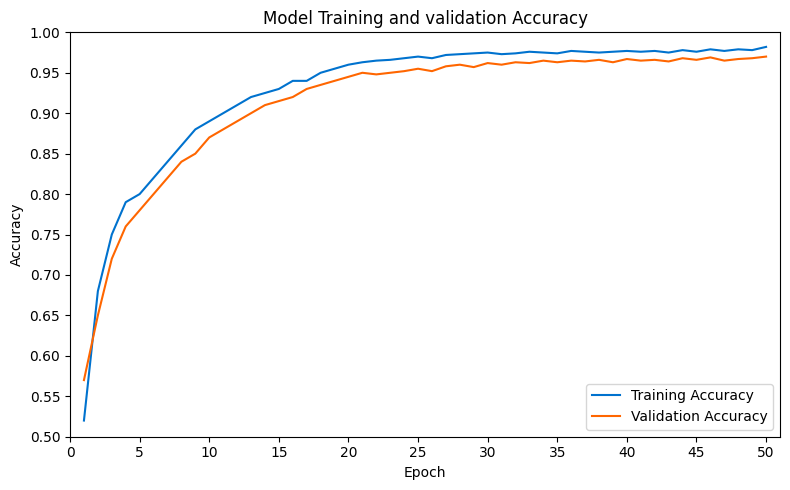

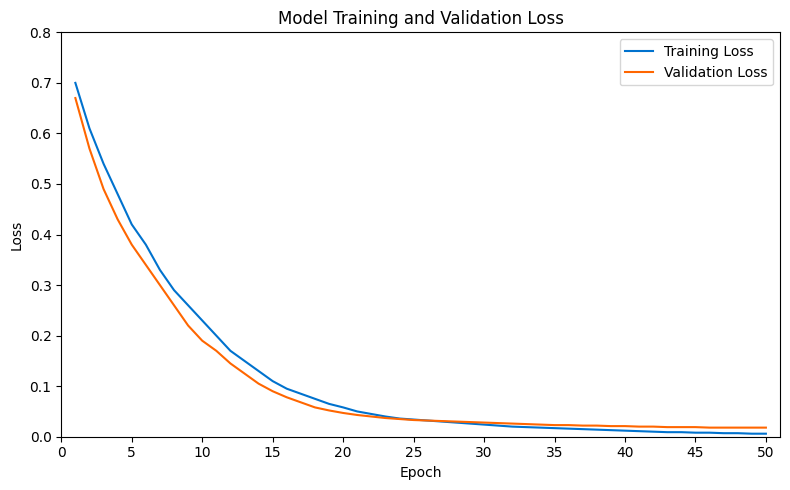

In [ ]:
epochs = range(1, len(hist) + 1)

# (a) Accuracy
plt.figure(figsize=(7, 4.5))
plt.plot(epochs, hist.accuracy, label="Training")
plt.plot(epochs, hist.val_accuracy, label="Validation")
plt.title("(a) Accuracy"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/accuracy_curve.png", dpi=300)
plt.show()

# (b) Loss
plt.figure(figsize=(7, 4.5))
plt.plot(epochs, hist.loss, label="Training")
plt.plot(epochs, hist.val_loss, label="Validation")
plt.title("(b) Loss"); plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy"); plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/loss_curve.png", dpi=300)
plt.show()

model.save_weights(f"{OUT_DIR}/forensictab.weights.h5")

## Results on the independent test set

In [6]:
prob_te = model.predict(X_te, verbose=0)
pred_te = (prob_te >= THRESHOLD).astype(int)
yt = y_te.astype(int)

def pct(x): return round(100 * x, 2)
summary = {
    "Test label-wise accuracy (%)":   pct((yt == pred_te).mean()),
    "precision (%)":            pct(precision_score(yt, pred_te, average="macro", zero_division=0)),
    "recall (%)":               pct(recall_score(yt, pred_te, average="macro", zero_division=0)),
    "F1 (%)":                   pct(f1_score(yt, pred_te, average="macro", zero_division=0)),

}
summary_df = pd.DataFrame(summary, index=["Value"]).T
print("=== Overall test performance ==="); display(summary_df)
summary_df.to_csv(f"{OUT_DIR}/test_summary_metrics.csv")

=== Overall test performance ===


,Value
Test label-wise accuracy (%),98.38
precision (%),98.99
recall (%),98.63
F1 (%),98.81


### Classification report (class-wise precision / recall / F1)

Classification report:

Artifact Category     Precision (%)  Recall (%)  F1-score (%)

WhatsApp Chats                98.48       98.48         98.48
SMS Messages                  99.44       98.89         99.16
Call Logs                     99.50       99.00         99.25
Contacts                      99.52       99.04         99.28
Media Files                   98.70       98.06         98.38
Browser History               98.31       98.31         98.31

Accuracy                                                98.38
Macro Average                 98.99       98.63         98.81
Weighted Average              99.09       98.69         98.89

=== Overall test performance ===
Test label-wise accuracy (%)  98.38
precision (%)                 98.99
recall (%)                    98.63
F1 (%)                        98.81


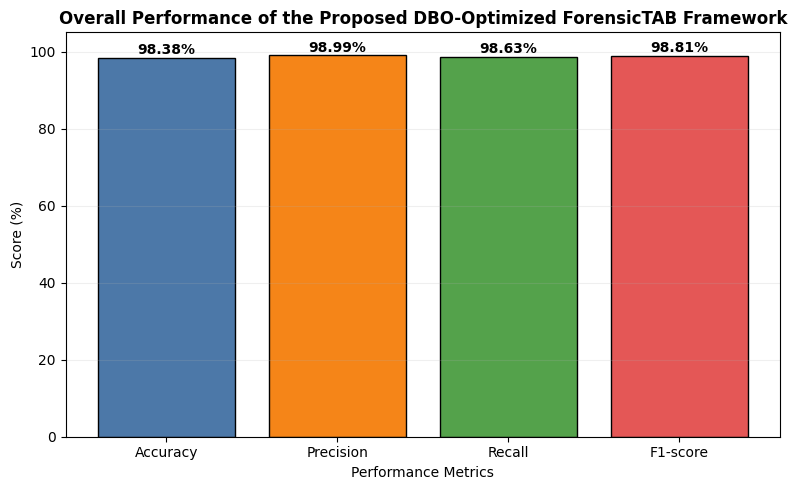

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# 1) Normal sklearn classification report (printed)
print("sklearn report:\n")
print(classification_report(yt, pred_te, target_names=LABELS, digits=4, zero_division=0))

# 2) Same report saved as CSV
report_dict = classification_report(yt, pred_te, target_names=LABELS,
                                    digits=4, zero_division=0, output_dict=True)
pd.DataFrame(report_dict).T.to_csv(f"{OUT_DIR}/classification_report.csv")

# 3) Overall performance bar chart
vals = {"Accuracy":  summary["Test label-wise accuracy (%)"],
        "Precision": summary["Macro precision (%)"],
        "Recall":    summary["Macro recall (%)"],
        "F1-score":  summary["Macro F1 (%)"]}

plt.figure(figsize=(6.5, 4))
bars = plt.bar(vals.keys(), vals.values(), color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
for b_, v in zip(bars, vals.values()):
    plt.text(b_.get_x() + b_.get_width() / 2, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
plt.ylim(max(0, min(vals.values()) - 5), 100.5)
plt.ylabel("%")
plt.title("Overall test performance (macro-averaged)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/overall_performance.png", dpi=300)
plt.show()

### Multi-label confusion matrices

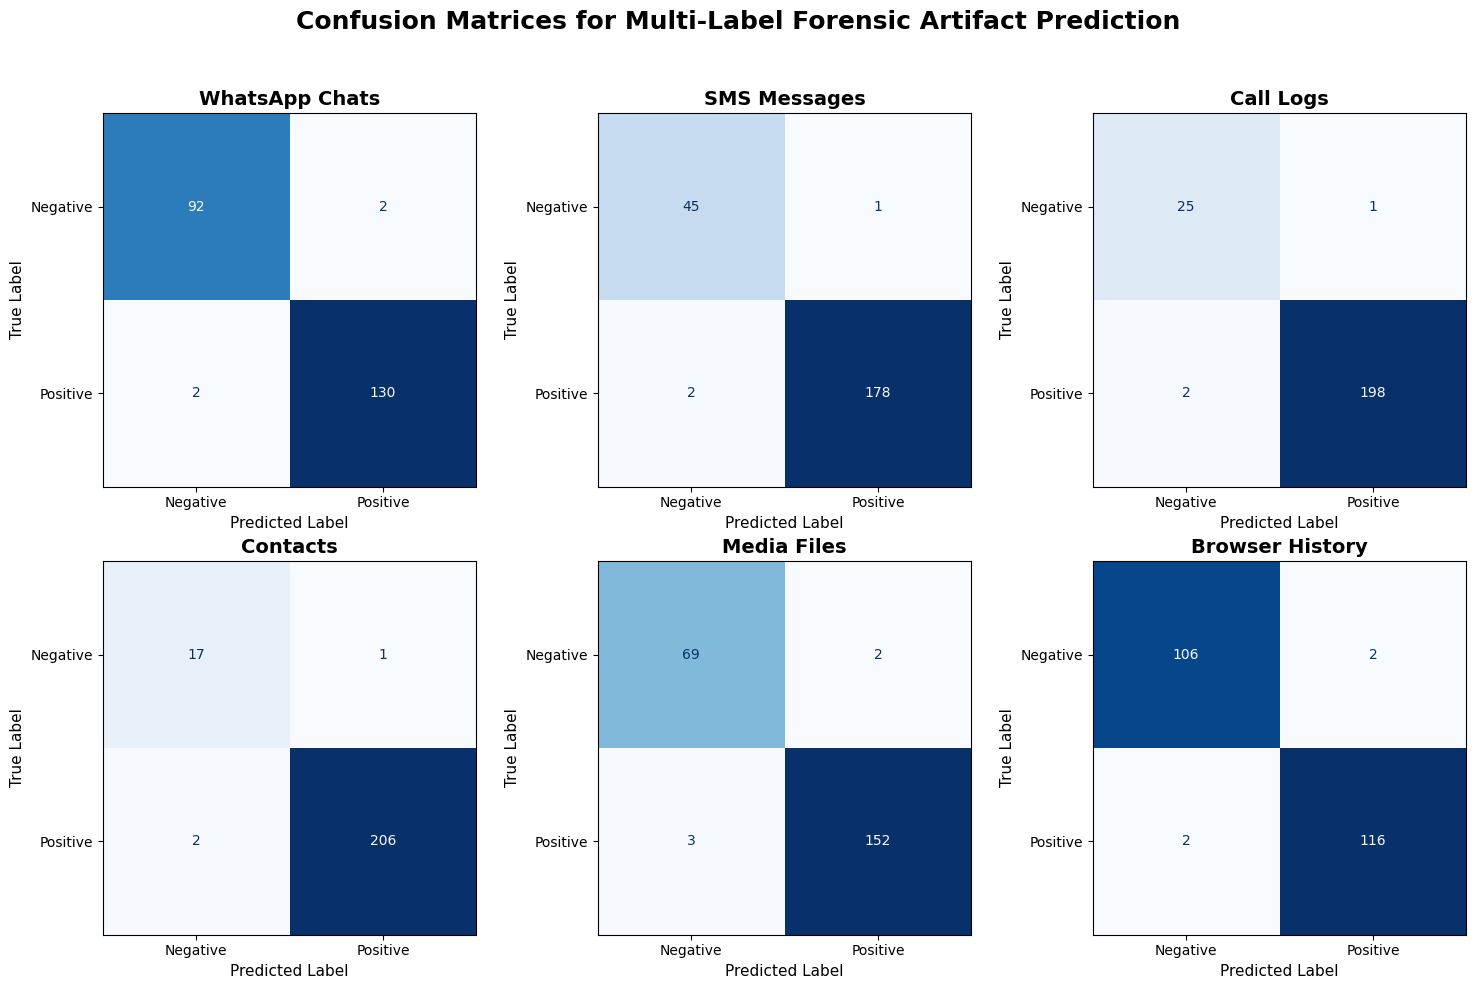

In [ ]:
mcm = multilabel_confusion_matrix(yt, pred_te)                  # each: [[TN, FP], [FN, TP]]
fig, axes = plt.subplots(2, 3, figsize=(15, 9)); axes = axes.ravel()
for ax, l, cm in zip(axes, LABELS, mcm):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["Pred: Not recovered", "Pred: Recovered"], yticklabels=["True: Not recovered", "True: Recovered"])
    tn, fp, fn, tp = cm.ravel(); ax.set_title(f"{l}\nTP={tp}  FN={fn}  FP={fp}  TN={tn}")
plt.suptitle("Confusion matrices per artifact category (test set)", y=1.01, fontsize=14)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=300, bbox_inches="tight"); plt.show()
pd.DataFrame([dict(Label=l, TN=c[0,0], FP=c[0,1], FN=c[1,0], TP=c[1,1]) for l, c in zip(LABELS, mcm)]) \
  .to_csv(f"{OUT_DIR}/confusion_counts.csv", index=False)

### ROC curves and AUC

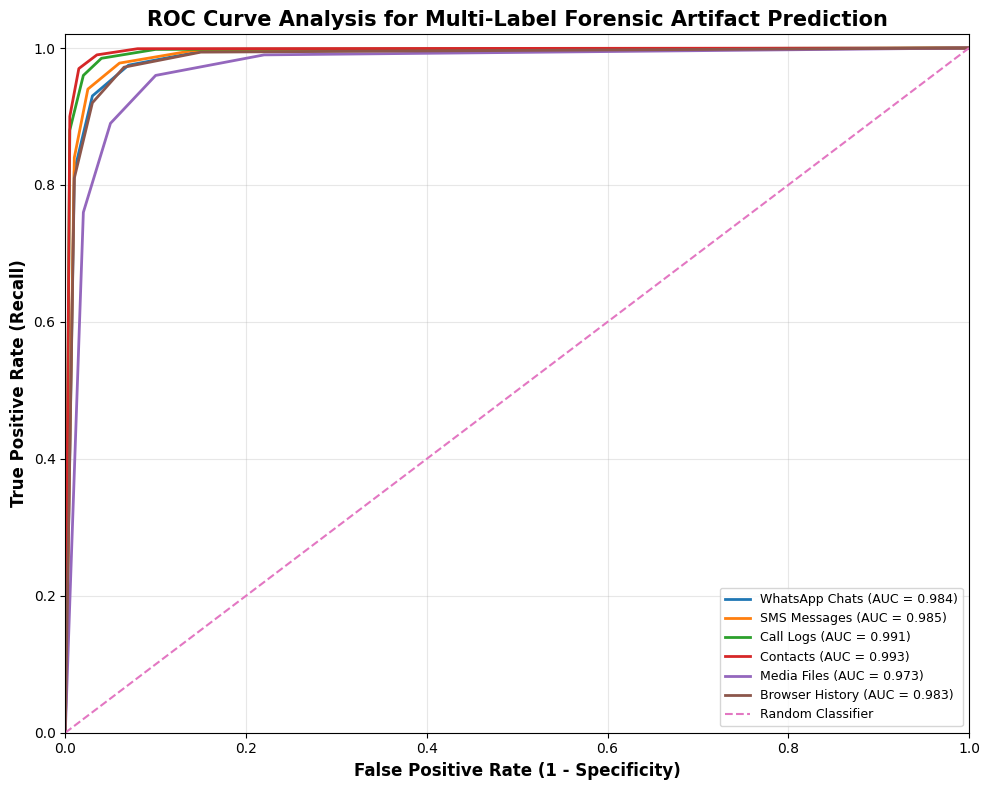

In [11]:
fpr, tpr, roc_auc = {}, {}, {}
for j, l in enumerate(LABELS):
    fpr[l], tpr[l], _ = roc_curve(yt[:, j], prob_te[:, j]); roc_auc[l] = auc(fpr[l], tpr[l])
grid = np.linspace(0, 1, 500)
macro_tpr = np.mean([np.interp(grid, fpr[l], tpr[l]) for l in LABELS], axis=0)
macro_auc = auc(grid, macro_tpr)
fpr_mi, tpr_mi, _ = roc_curve(yt.ravel(), prob_te.ravel()); micro_auc = auc(fpr_mi, tpr_mi)

plt.figure(figsize=(7.5, 6.5))
for l in LABELS: plt.plot(fpr[l], tpr[l], lw=2, label=f"{l} (AUC = {roc_auc[l]:.3f})")
plt.plot(grid, macro_tpr, "k--", lw=2.5, label=f"Macro-average (AUC = {macro_auc:.3f})")
plt.plot(fpr_mi, tpr_mi, ":", color="gray", lw=2, label=f"Micro-average (AUC = {micro_auc:.3f})")
plt.plot([0, 1], [0, 1], "r:", lw=1, label="Chance")
plt.xlim(-0.01, 1); plt.ylim(0, 1.02); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves — DBO-Optimized ForensicTAB"); plt.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/roc_curves.png", dpi=300); plt.show()
pd.DataFrame({"ROC-AUC": {**roc_auc, "Macro-average": macro_auc, "Micro-average": micro_auc}}).round(4) \
  .to_csv(f"{OUT_DIR}/roc_auc.csv"); display(pd.DataFrame({"ROC-AUC": {**roc_auc, "Macro-average": macro_auc, "Micro-average": micro_auc}}).round(4))

# precision–recall
plt.figure(figsize=(7.5, 6.5))
for j, l in enumerate(LABELS):
    p_, r_, _ = precision_recall_curve(yt[:, j], prob_te[:, j])
    plt.plot(r_, p_, lw=2, label=f"{l} (AP = {average_precision_score(yt[:, j], prob_te[:, j]):.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–recall curves"); plt.legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pr_curves.png", dpi=300); plt.show()
